# Análisis de datos — Plataforma de empleos

**Base de Datos Aplicada (UCC) · Entrega 4**
**Integrantes:** Facundo Grillo, María Emilia Lasa, Gonzalo Marín

Este notebook se conecta a la base MongoDB del proyecto, recupera los datos con PyMongo, los prepara con Pandas y responde cuatro preguntas del dominio con indicadores y gráficos:

| # | Pregunta | Para qué decisión sirve |
| :--- | :--- | :--- |
| 1 | ¿Qué skills piden las empresas que escasean entre los candidatos? | Qué perfiles atraer o capacitar |
| 2 | ¿La coincidencia de skills anticipa quién termina contratado? | Si conviene recomendar candidatos por *matching* |
| 3 | ¿Lo que pretenden ganar los candidatos está alineado con lo que ofrecen las empresas? | Cómo orientar las bandas salariales publicadas |
| 4 | ¿Cómo evoluciona la actividad y cuánto tarda en cubrirse una vacante? | Dónde está el cuello de botella del proceso |

**Cómo ejecutarlo:** con la base cargada (`bin/reset_db.sh`), `docker compose up -d analisis` y abrir <http://localhost:8888>. Para regenerarlo completo sin abrir el navegador: `docker compose run --rm analisis jupyter nbconvert --to notebook --execute --inplace analisis.ipynb`.

> **Sobre los datos.** Son los 450 documentos sintéticos del proyecto, generados con semilla fija por `seed/generar_datos.py` con fecha de referencia 27/10/2026. Algunas relaciones están inducidas por las reglas del generador; en cada conclusión indicamos cuáles. Lo que el notebook demuestra es el **método**: con datos reales, el mismo código daría los valores reales.

## 1. Conexión y recuperación de datos

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from pymongo import MongoClient

pd.set_option("display.precision", 2)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({
    "figure.figsize": (9, 5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
})
AZUL, NARANJA, GRIS, VERDE = "#2563eb", "#f59e0b", "#9ca3af", "#16a34a"
SENIORITIES = ["junior", "semi-senior", "senior", "lead"]
FECHA_REFERENCIA = pd.Timestamp("2026-10-27 12:00", tz="UTC")  # la misma que usa el generador de datos

os.makedirs("figuras", exist_ok=True)


def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(f"figuras/{nombre}.png", dpi=150, bbox_inches="tight")


cliente = MongoClient(os.environ.get("MONGO_URI", "mongodb://localhost:27017/?directConnection=true"), tz_aware=True)
db = cliente[os.environ.get("MONGO_DB", "empleos")]
{nombre: db[nombre].count_documents({}) for nombre in ["empresas", "usuarios", "ofertas", "postulaciones"]}

{'empresas': 20, 'usuarios': 120, 'ofertas': 60, 'postulaciones': 250}

Se recuperan sólo los campos que usa el análisis (proyección en MongoDB) y `pd.json_normalize` aplana los subdocumentos: por ejemplo, `salario.min` o `preferencias.salarioPretendido.monto` pasan a ser columnas. Los arreglos (`skills`, `historialEstados`) quedan como listas dentro de la celda y se expanden cuando hace falta.

In [2]:
usuarios = pd.json_normalize(list(db.usuarios.find(
    {}, {"seniority": 1, "skills": 1, "ubicacion": 1, "preferencias": 1, "experiencia": 1})))
ofertas = pd.json_normalize(list(db.ofertas.find({}, {"descripcion": 0})))
postulaciones = pd.json_normalize(list(db.postulaciones.find()))

print("usuarios     ", usuarios.shape)
print("ofertas      ", ofertas.shape)
print("postulaciones", postulaciones.shape)
ofertas[["titulo", "empresa.nombre", "seniority", "modalidad", "salario.min", "salario.max",
         "salario.moneda", "vacantes.total", "vacantes.disponibles", "estado"]].head()

usuarios      (120, 12)
ofertas       (60, 23)
postulaciones (250, 12)


,titulo,empresa.nombre,seniority,modalidad,salario.min,salario.max,salario.moneda,vacantes.total,vacantes.disponibles,estado
0,Backend Developer Jr,Andes Data Labs,junior,hibrido,NaN,NaN,NaN,1,0,cerrada
1,Desarrollador/a Backend Jr,Brújula Fintech,junior,hibrido,9.90e+05,1.20e+06,ARS,1,1,abierta
2,Desarrollador/a Backend Sr,Molle Tech,senior,presencial,NaN,NaN,NaN,1,1,cerrada
3,Desarrollador/a Backend Jr,Cóndor Cloud,junior,remoto,1.26e+06,1.80e+06,ARS,1,0,cerrada
4,Backend Developer Lead,Brújula Fintech,lead,hibrido,3.60e+06,4.39e+06,ARS,3,2,abierta


## 2. Preparación de los datos

Antes de calcular indicadores revisamos qué tan completos están los campos opcionales, porque determinan sobre cuántos documentos se calcula cada indicador.

In [3]:
calidad = pd.Series({
    "Ofertas sin salario publicado": ofertas["salario.min"].isna().mean(),
    "Ofertas con salario en USD": (ofertas["salario.moneda"] == "USD").mean(),
    "Usuarios sin preferencias": usuarios["preferencias.disponible"].isna().mean(),
    "Usuarios sin salario pretendido": usuarios["preferencias.salarioPretendido.monto"].isna().mean(),
    "Usuarios sin skills": (usuarios["skills"].str.len() == 0).mean(),
    "Usuarios sin experiencia": (usuarios["experiencia"].str.len() == 0).mean(),
}, name="% de documentos")
(calidad * 100).round(1).to_frame()

,% de documentos
Ofertas sin salario publicado,30.0
Ofertas con salario en USD,10.0
Usuarios sin preferencias,16.7
Usuarios sin salario pretendido,35.0
Usuarios sin skills,1.7
Usuarios sin experiencia,13.3


In [4]:
# Campos derivados
ofertas["salario_medio"] = (ofertas["salario.min"] + ofertas["salario.max"]) / 2
ofertas["seniority"] = pd.Categorical(ofertas["seniority"], SENIORITIES, ordered=True)
usuarios["seniority"] = pd.Categorical(usuarios["seniority"], SENIORITIES, ordered=True)

estados_recorridos = postulaciones["historialEstados"].apply(lambda h: {e["estado"] for e in h})
postulaciones["paso_por_revision"] = estados_recorridos.apply(lambda e: "en_revision" in e)
postulaciones["paso_por_entrevista"] = estados_recorridos.apply(lambda e: "entrevista" in e)
postulaciones["dias_hasta_respuesta"] = postulaciones["historialEstados"].apply(
    lambda h: (h[1]["fecha"] - h[0]["fecha"]).total_seconds() / 86400 if len(h) > 1 else None)
postulaciones["tramo_coincidencia"] = pd.cut(
    postulaciones["coincidenciaSkills"], bins=[-0.01, 0.34, 0.66, 1.0],
    labels=["baja (≤ 33 %)", "media (34–66 %)", "alta (≥ 67 %)"])

postulaciones[["estado", "coincidenciaSkills", "tramo_coincidencia", "paso_por_entrevista",
               "dias_hasta_respuesta"]].head()

,estado,coincidenciaSkills,tramo_coincidencia,paso_por_entrevista,dias_hasta_respuesta
0,enviada,0.00,baja (≤ 33 %),False,NaN
1,enviada,0.33,baja (≤ 33 %),False,NaN
2,rechazada,1.00,alta (≥ 67 %),True,1.00
3,rechazada,0.20,baja (≤ 33 %),False,7.08
4,retirada,0.33,baja (≤ 33 %),False,4.08


## 3. Indicadores

### 3.1. Brecha de skills: lo que piden las empresas frente a lo que tienen los candidatos

Este cálculo se hace **dentro de MongoDB** con un pipeline de agregación (es la consulta 8 de la Entrega 2, sin el `$facet`) y sólo el resultado se trae a Pandas. Para cada skill se compara:

- **% de ofertas** que la mencionan (requerida o deseable),
- **% de usuarios** que la tienen,
- **candidatos por oferta**: cuántos usuarios con esa skill hay por cada oferta que la pide. Cuanto más bajo, más escasa.

In [5]:
total_ofertas = db.ofertas.count_documents({})
total_usuarios = db.usuarios.count_documents({})

pipeline_brecha = [
    {"$project": {"skill": {"$setUnion": ["$skillsRequeridas", {"$ifNull": ["$skillsDeseables", []]}]}}},
    {"$unwind": "$skill"},
    {"$group": {"_id": "$skill", "ofertas": {"$sum": 1}}},
    {"$unionWith": {"coll": "usuarios", "pipeline": [
        {"$unwind": "$skills"}, {"$group": {"_id": "$skills", "usuarios": {"$sum": 1}}}]}},
    {"$group": {"_id": "$_id", "ofertas": {"$sum": "$ofertas"}, "usuarios": {"$sum": "$usuarios"}}},
]
brecha = pd.DataFrame(db.ofertas.aggregate(pipeline_brecha)).rename(columns={"_id": "skill"}).set_index("skill")
brecha["% ofertas"] = brecha["ofertas"] / total_ofertas * 100
brecha["% usuarios"] = brecha["usuarios"] / total_usuarios * 100
brecha["brecha (pp)"] = brecha["% ofertas"] - brecha["% usuarios"]
brecha["candidatos por oferta"] = brecha["usuarios"] / brecha["ofertas"]
brecha = brecha.sort_values("brecha (pp)", ascending=False)

relevantes = brecha[brecha["ofertas"] >= 5]  # skills pedidas por al menos 5 ofertas
print("Más escasas (pedidas por >= 5 ofertas, menos candidatos por oferta):")
display(relevantes.sort_values("candidatos por oferta").head(6).round(1))
print("Más abundantes:")
display(relevantes.sort_values("candidatos por oferta", ascending=False).head(4).round(1))

Más escasas (pedidas por >= 5 ofertas, menos candidatos por oferta):


,ofertas,usuarios,% ofertas,% usuarios,brecha (pp),candidatos por oferta
skill,,,,,,
next.js,9,1,15.0,0.8,14.2,0.1
typescript,10,7,16.7,5.8,10.8,0.7
cypress,7,6,11.7,5.0,6.7,0.9
aws,19,17,31.7,14.2,17.5,0.9
react,11,12,18.3,10.0,8.3,1.1
kotlin,6,7,10.0,5.8,4.2,1.2


Más abundantes:


,ofertas,usuarios,% ofertas,% usuarios,brecha (pp),candidatos por oferta
skill,,,,,,
git,14,86,23.3,71.7,-48.3,6.1
scrum,11,58,18.3,48.3,-30.0,5.3
jira,9,41,15.0,34.2,-19.2,4.6
spring,5,16,8.3,13.3,-5.0,3.2


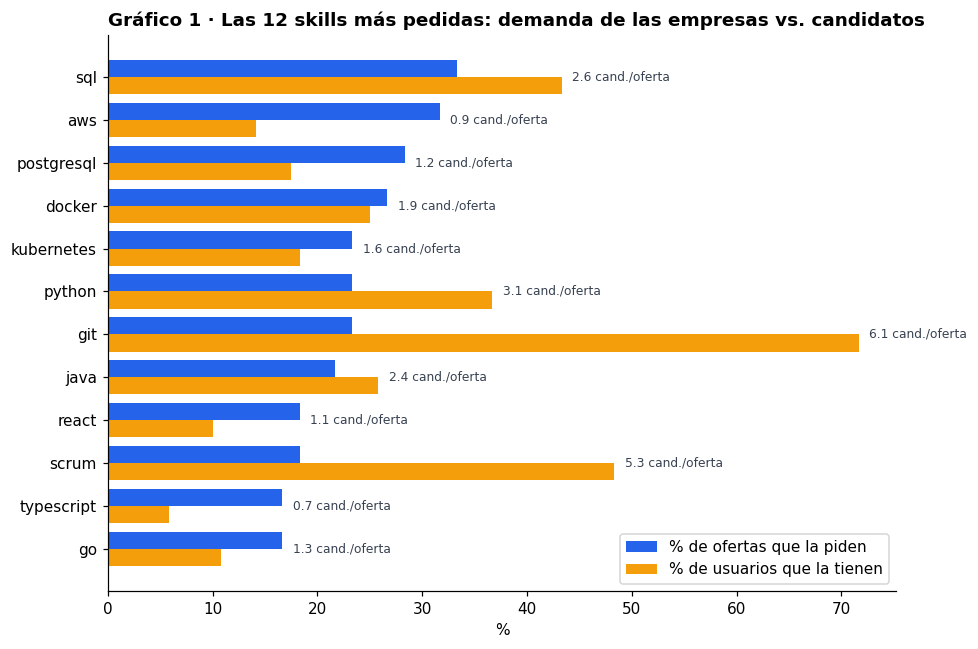

In [6]:
top = brecha.sort_values("% ofertas", ascending=False).head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
y = range(len(top))
ax.barh([i + 0.2 for i in y], top["% ofertas"], height=0.4, color=AZUL, label="% de ofertas que la piden")
ax.barh([i - 0.2 for i in y], top["% usuarios"], height=0.4, color=NARANJA, label="% de usuarios que la tienen")
ax.set_yticks(list(y), top.index)
ax.set_xlabel("%")
ax.set_title("Gráfico 1 · Las 12 skills más pedidas: demanda de las empresas vs. candidatos")
for i, (_, fila) in enumerate(top.iterrows()):
    ax.text(max(fila["% ofertas"], fila["% usuarios"]) + 1, i, f"{fila['candidatos por oferta']:.1f} cand./oferta",
            va="center", fontsize=8, color="#374151")
ax.legend(loc="lower right")
guardar(fig, "1_brecha_skills")
plt.show()

**Qué muestra.**

- Las skills más escasas en relación con la demanda son **Next.js** (0,1 candidatos por oferta: la piden 9 ofertas y la tiene 1 solo usuario), **TypeScript** (0,7), **AWS** y **Cypress** (0,9). AWS es además la de mayor brecha absoluta: la piden el **31,7 %** de las ofertas y la tiene el **14,2 %** de los usuarios (+17,5 puntos).
- En el otro extremo, **git, scrum y jira** las tienen el 72 %, 48 % y 34 % de los candidatos, y las ofertas casi siempre las piden sólo como deseables: no diferencian a un candidato de otro.
- **SQL y Python** son muy pedidas pero también abundantes (2,6 y 3,1 candidatos por oferta): no son un cuello de botella.

**Lectura.** El faltante de talento se concentra en dos áreas: **cloud** (AWS) y **frontend moderno** (TypeScript, Next.js, React).

> *Advertencia:* el generador de datos asigna a cada skill un peso distinto en perfiles y en ofertas, así que esta brecha fue inducida a propósito. Lo que se valida acá es que el indicador la detecta.

### 3.2. Embudo de selección y coincidencia de skills

Dos indicadores a partir del **historial de estados embebido** en cada postulación:

- **Embudo:** qué proporción de las postulaciones llega a cada etapa (revisión, entrevista, aceptación).
- **Tasa de aceptación según la coincidencia de skills**, calculada sobre las postulaciones ya decididas (aceptadas + rechazadas): ¿los candidatos que más coinciden con la oferta son los que se contratan?

In [7]:
embudo = pd.Series({
    "Postulaciones": len(postulaciones),
    "Llegaron a revisión": postulaciones["paso_por_revision"].sum(),
    "Llegaron a entrevista": postulaciones["paso_por_entrevista"].sum(),
    "Aceptadas": (postulaciones["estado"] == "aceptada").sum(),
}, name="cantidad").to_frame()
embudo["% del total"] = embudo["cantidad"] / len(postulaciones) * 100
display(embudo.round(1))

decididas = postulaciones[postulaciones["estado"].isin(["aceptada", "rechazada"])]
por_tramo = decididas.groupby("tramo_coincidencia", observed=False).agg(
    decididas=("estado", "size"),
    aceptadas=("estado", lambda e: (e == "aceptada").sum()),
    entrevistadas=("paso_por_entrevista", "sum"))
por_tramo["tasa de aceptación %"] = por_tramo["aceptadas"] / por_tramo["decididas"] * 100
por_tramo["tasa de entrevista %"] = por_tramo["entrevistadas"] / por_tramo["decididas"] * 100
print("Coincidencia promedio — aceptadas:", round(decididas.loc[decididas.estado == "aceptada", "coincidenciaSkills"].mean(), 2),
      "| rechazadas:", round(decididas.loc[decididas.estado == "rechazada", "coincidenciaSkills"].mean(), 2))
por_tramo.round(1)

,cantidad,% del total
Postulaciones,250,100.0
Llegaron a revisión,151,60.4
Llegaron a entrevista,75,30.0
Aceptadas,25,10.0


Coincidencia promedio — aceptadas: 0.8 | rechazadas: 0.35


,decididas,aceptadas,entrevistadas,tasa de aceptación %,tasa de entrevista %
tramo_coincidencia,,,,,
baja (≤ 33 %),43,0,15,0.0,34.9
media (34–66 %),23,6,14,26.1,60.9
alta (≥ 67 %),32,19,23,59.4,71.9


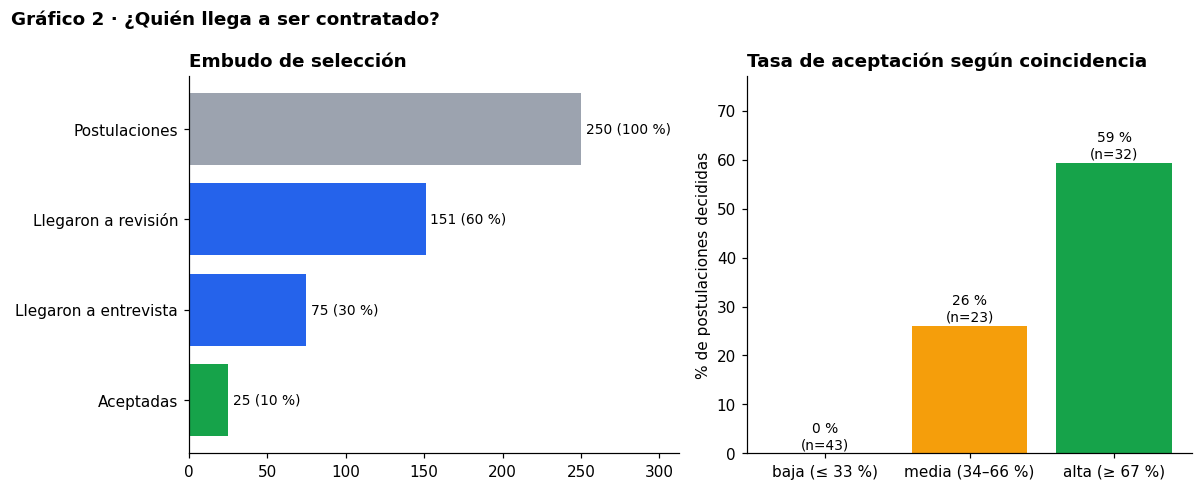

In [8]:
fig, (izq, der) = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [1.1, 1]})

etapas = embudo.iloc[::-1]
izq.barh(etapas.index, etapas["cantidad"], color=[VERDE, AZUL, AZUL, GRIS])
for i, (cantidad, pct) in enumerate(zip(etapas["cantidad"], etapas["% del total"])):
    izq.text(cantidad + 3, i, f"{cantidad} ({pct:.0f} %)", va="center", fontsize=9)
izq.set_title("Embudo de selección")
izq.set_xlim(0, embudo["cantidad"].max() * 1.25)

der.bar(por_tramo.index.astype(str), por_tramo["tasa de aceptación %"], color=[GRIS, NARANJA, VERDE])
for i, (tasa, n) in enumerate(zip(por_tramo["tasa de aceptación %"], por_tramo["decididas"])):
    der.text(i, tasa + 1, f"{tasa:.0f} %\n(n={n})", ha="center", fontsize=9)
der.set_title("Tasa de aceptación según coincidencia")
der.set_ylabel("% de postulaciones decididas")
der.set_ylim(0, max(por_tramo["tasa de aceptación %"].max() * 1.3, 10))

fig.suptitle("Gráfico 2 · ¿Quién llega a ser contratado?", fontweight="bold", x=0.01, ha="left")
guardar(fig, "2_embudo_coincidencia")
plt.show()

**Qué muestra.**

- De 250 postulaciones, el **60 %** llegó a revisión, el **30 %** a entrevista y el **10 %** terminó en contratación.
- Entre las postulaciones ya decididas, la tasa de aceptación crece con la coincidencia de skills: **0 %** en el tramo bajo, **26 %** en el medio y **59 %** en el alto. La coincidencia promedio de los aceptados es 0,80 y la de los rechazados, 0,35.
- Lo mismo pasa con llegar a entrevista: 35 % → 61 % → 72 %.
- Las 43 postulaciones decididas con coincidencia baja terminaron todas rechazadas: es trabajo de revisión de los reclutadores que no produjo ninguna contratación.

**Lectura.** La coincidencia que se calcula al postularse (y que guardamos desnormalizada en la postulación) **anticipa bien quién es contratado**. Eso justifica usarla para recomendar candidatos (consulta 10 de la Entrega 2) y para ordenar a los postulantes, como ya hace `GET /ofertas/{id}/postulaciones`.

> *Advertencia:* el generador sólo acepta candidatos con coincidencia de al menos 50 %, por eso el 0 % del tramo bajo es exacto. Con datos reales esperaríamos la misma dirección, pero no un corte tan limpio.

### 3.3. Salario ofrecido vs. salario pretendido

Se comparan, por seniority y sólo en pesos (ARS, la gran mayoría):

- el **salario ofrecido**: punto medio de la banda publicada en cada oferta (`salario.min` y `salario.max`);
- el **salario pretendido** que declaran los candidatos en `preferencias.salarioPretendido`.

Se usan **medianas**, que no se distorsionan con valores extremos. La **brecha** es cuánto más (o menos) pretenden los candidatos respecto de lo que se ofrece.

In [9]:
ofrecido = ofertas[ofertas["salario.moneda"] == "ARS"]
pretendido = usuarios[usuarios["preferencias.salarioPretendido.moneda"] == "ARS"]

salarios = pd.DataFrame({
    "ofertas": ofrecido.groupby("seniority", observed=False).size(),
    "mediana ofrecida": ofrecido.groupby("seniority", observed=False)["salario_medio"].median(),
    "candidatos": pretendido.groupby("seniority", observed=False).size(),
    "mediana pretendida": pretendido.groupby("seniority", observed=False)["preferencias.salarioPretendido.monto"].median(),
})
salarios["brecha %"] = (salarios["mediana pretendida"] / salarios["mediana ofrecida"] - 1) * 100
display(salarios.round(0))

# ¿Publicar el salario atrae más postulaciones? (ofertas ya cerradas o con al menos 30 días publicadas)
maduras = ofertas[(FECHA_REFERENCIA - ofertas["fechaPublicacion"]).dt.days >= 30]
publicacion = maduras.groupby(maduras["salario.min"].notna().map({True: "con salario", False: "sin salario"}))[
    "cantidadPostulaciones"].agg(["count", "mean", "median"])
publicacion.columns = ["ofertas", "postulaciones promedio", "postulaciones mediana"]
publicacion.round(1)

,ofertas,mediana ofrecida,candidatos,mediana pretendida,brecha %
seniority,,,,,
junior,10,1.35e+06,23,1.20e+06,-11.0
semi-senior,11,1.94e+06,24,1.88e+06,-3.0
senior,8,3.15e+06,12,3.15e+06,0.0
lead,7,4.10e+06,9,4.25e+06,4.0


,ofertas,postulaciones promedio,postulaciones mediana
salario.min,,,
con salario,35,2.7,2.0
sin salario,14,4.3,4.5


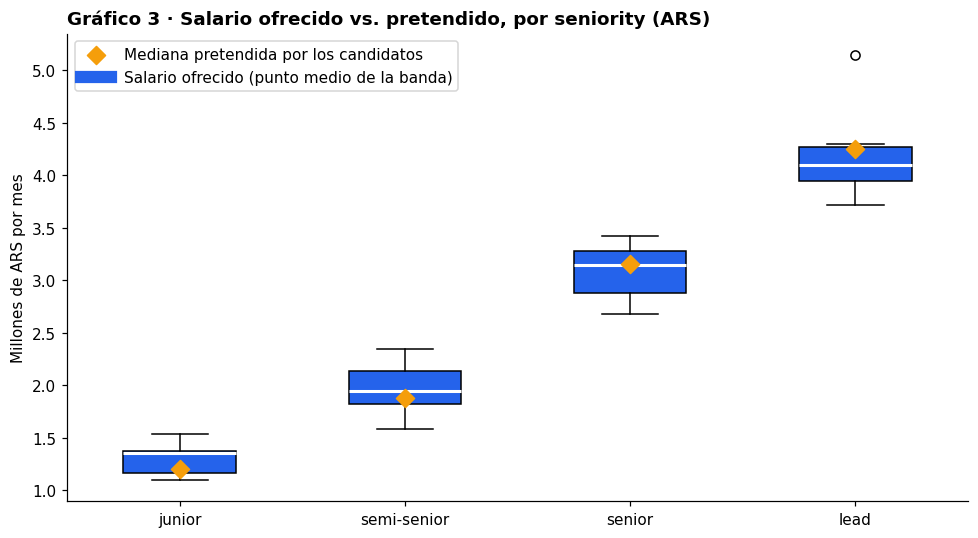

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
datos = [ofrecido.loc[ofrecido["seniority"] == s, "salario_medio"] / 1e6 for s in SENIORITIES]
caja = ax.boxplot(datos, tick_labels=SENIORITIES, patch_artist=True, widths=0.5,
                  medianprops={"color": "white", "linewidth": 2})
for parte in caja["boxes"]:
    parte.set_facecolor(AZUL)
ax.scatter(range(1, 5), salarios["mediana pretendida"] / 1e6, marker="D", s=70, color=NARANJA, zorder=3,
           label="Mediana pretendida por los candidatos")
ax.plot([], [], color=AZUL, linewidth=8, label="Salario ofrecido (punto medio de la banda)")
ax.set_ylabel("Millones de ARS por mes")
ax.set_title("Gráfico 3 · Salario ofrecido vs. pretendido, por seniority (ARS)")
ax.legend(loc="upper left")
guardar(fig, "3_salarios")
plt.show()

**Qué muestra.**

- Las expectativas están **alineadas** con lo que se ofrece: la diferencia entre medianas va de **−11 %** (los junior pretenden menos de lo que se les ofrece) a **+4 %** (los lead pretenden un poco más). En senior coinciden.
- La dispersión de lo ofrecido crece con el seniority: la banda de lead es la más amplia y tiene un valor atípico de ≈ 5,1 millones.
- **¿Publicar el salario atrae más postulaciones?** En las ofertas con al menos 30 días publicadas, las que **no** muestran salario recibieron en promedio **más** postulaciones (4,3 contra 2,7). Es lo contrario de lo esperable, pero hay sólo 14 ofertas sin salario y el generador asigna la popularidad de cada oferta al azar, sin relación con el salario. **No corresponde sacar una conclusión**: es un buen ejemplo de por qué un número no alcanza si no se entiende cómo se generaron los datos.

**Lectura.** El salario no explica los rechazos: no hay un desajuste sistemático entre lo que piden los candidatos y lo que pagan las empresas. Los grupos son chicos (entre 7 y 11 ofertas por seniority), así que las medianas son orientativas.

### 3.4. Actividad mensual y tiempo de cobertura

- **Actividad:** ofertas publicadas y postulaciones recibidas por mes.
- **Tiempo de cobertura:** días entre la publicación y el cierre de las ofertas que **cubrieron todas sus vacantes**.
- **Tiempo de primera respuesta:** días entre que el candidato se postula y el primer cambio de estado.
- **Competencia:** postulaciones activas por vacante disponible en las ofertas abiertas.

In [11]:
mes = lambda fechas: fechas.dt.tz_convert(None).dt.to_period("M")
actividad = pd.DataFrame({
    "ofertas publicadas": ofertas.groupby(mes(ofertas["fechaPublicacion"])).size(),
    "postulaciones": postulaciones.groupby(mes(postulaciones["fechaPostulacion"])).size(),
}).fillna(0).astype(int)
actividad["postulaciones por oferta publicada"] = actividad["postulaciones"] / actividad["ofertas publicadas"]
display(actividad.T.round(1))

cubiertas = ofertas[(ofertas["estado"] == "cerrada") & (ofertas["vacantes.disponibles"] == 0)]
dias_cobertura = (cubiertas["fechaCierre"] - cubiertas["fechaPublicacion"]).dt.total_seconds() / 86400
abiertas = ofertas[ofertas["estado"] == "abierta"]
activas = postulaciones[postulaciones["estado"].isin(["enviada", "en_revision", "entrevista"])]
competencia = activas.groupby("ofertaId").size().reindex(abiertas["_id"], fill_value=0).values / abiertas["vacantes.disponibles"].values

tiempos = pd.Series({
    "Ofertas que cubrieron todas sus vacantes": len(cubiertas),
    "Días hasta cubrir — mediana": dias_cobertura.median(),
    "Días hasta cubrir — mínimo": dias_cobertura.min(),
    "Días hasta cubrir — máximo": dias_cobertura.max(),
    "Días hasta la primera respuesta — mediana": postulaciones["dias_hasta_respuesta"].median(),
    "Postulaciones sin ninguna respuesta todavía": (postulaciones["estado"] == "enviada").sum(),
    "Postulaciones activas por vacante (ofertas abiertas) — mediana": pd.Series(competencia).median(),
    "Ofertas abiertas sin postulaciones activas": int((competencia == 0).sum()),
})
tiempos.round(1).to_frame("valor")

,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
ofertas publicadas,5.0,6.0,7.0,11.0,9.0,11.0,11.0
postulaciones,5.0,10.0,13.0,17.0,33.0,43.0,129.0
postulaciones por oferta publicada,1.0,1.7,1.9,1.5,3.7,3.9,11.7


,valor
Ofertas que cubrieron todas sus vacantes,10.0
Días hasta cubrir — mediana,36.4
Días hasta cubrir — mínimo,10.7
Días hasta cubrir — máximo,58.5
Días hasta la primera respuesta — mediana,3.6
Postulaciones sin ninguna respuesta todavía,58.0
Postulaciones activas por vacante (ofertas abiertas) — mediana,2.0
Ofertas abiertas sin postulaciones activas,5.0


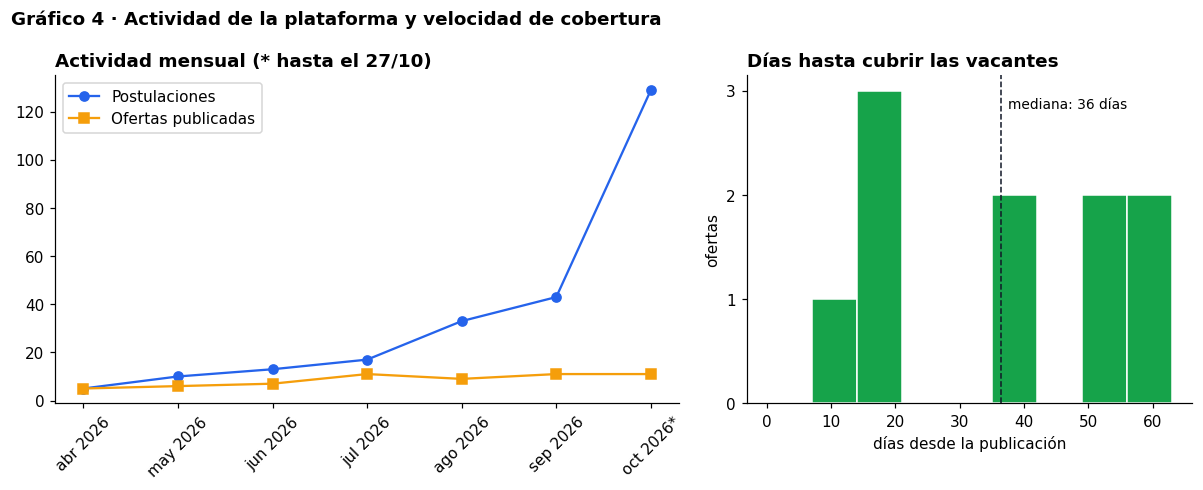

In [12]:
from matplotlib.ticker import MaxNLocator

fig, (izq, der) = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})

MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
etiquetas = [f"{MESES[p.month - 1]} {p.year}" for p in actividad.index]
etiquetas[-1] += "*"  # mes en curso: datos hasta la fecha de referencia
izq.plot(etiquetas, actividad["postulaciones"], marker="o", color=AZUL, label="Postulaciones")
izq.plot(etiquetas, actividad["ofertas publicadas"], marker="s", color=NARANJA, label="Ofertas publicadas")
izq.set_title("Actividad mensual (* hasta el 27/10)")
izq.tick_params(axis="x", rotation=45)
izq.legend()

der.hist(dias_cobertura, bins=range(0, int(dias_cobertura.max()) + 10, 7), color=VERDE, edgecolor="white")
der.axvline(dias_cobertura.median(), color="#111827", linestyle="--", linewidth=1)
der.text(dias_cobertura.median() + 1, der.get_ylim()[1] * 0.9, f"mediana: {dias_cobertura.median():.0f} días", fontsize=9)
der.set_title("Días hasta cubrir las vacantes")
der.set_xlabel("días desde la publicación")
der.set_ylabel("ofertas")
der.yaxis.set_major_locator(MaxNLocator(integer=True))

fig.suptitle("Gráfico 4 · Actividad de la plataforma y velocidad de cobertura", fontweight="bold", x=0.01, ha="left")
guardar(fig, "4_actividad_cobertura")
plt.show()

**Qué muestra.**

- Las postulaciones crecen mucho más rápido que las ofertas: se pasó de **1 postulación por oferta publicada** en abril a **11,7** en octubre (mes parcial, hasta el 27). Una parte se explica porque las ofertas abiertas siguen acumulando postulaciones durante varios meses, y otra porque el generador concentra la mayoría de las ofertas en los últimos meses.
- Las 10 ofertas que cubrieron todas sus vacantes tardaron una **mediana de 36 días** (entre 11 y 59).
- La primera respuesta al candidato llega en una mediana de **3,6 días**, pero **58 postulaciones (23 %) siguen en "enviada"** sin ninguna respuesta, muchas de ellas recientes.
- En las ofertas abiertas hay una mediana de **2 postulaciones activas por vacante**, y **5 ofertas abiertas no tienen ningún postulante activo**.

**Lectura.** El cuello de botella no es la cantidad de postulaciones sino dónde están: hay postulaciones que esperan respuesta y, a la vez, ofertas abiertas sin candidatos. Las dos cosas se pueden atacar con las herramientas que ya tiene el proyecto: el ranking por coincidencia y el *matching*.

## 4. Resumen de indicadores

| Pregunta | Indicador | Valor |
| :--- | :--- | :--- |
| 1. Skills | Candidatos por oferta en las skills más escasas | Next.js 0,1 · TypeScript 0,7 · AWS 0,9 · Cypress 0,9 |
| 1. Skills | Mayor brecha (% ofertas − % usuarios) | AWS: +17,5 puntos |
| 2. Selección | Conversión postulación → contratación | 10 % (25 de 250) |
| 2. Selección | Tasa de aceptación según coincidencia (baja / media / alta) | 0 % / 26 % / 59 % |
| 3. Salarios | Diferencia mediana pretendida vs. ofrecida | de −11 % (junior) a +4 % (lead) |
| 3. Salarios | Ofertas que no publican salario | 30 % |
| 4. Proceso | Días hasta cubrir todas las vacantes (mediana) | 36 días |
| 4. Proceso | Postulaciones sin ninguna respuesta | 58 (23 %) |
| 4. Proceso | Ofertas abiertas sin postulantes activos | 5 |

## 5. Conclusiones y recomendaciones

### Recomendación principal

**Incorporar a la plataforma la recomendación activa de candidatos por coincidencia de skills**, empezando por las ofertas abiertas que no tienen postulantes activos y por las que piden skills escasas.

Se apoya en tres resultados:

1. La coincidencia de skills **anticipa la contratación**: 59 % de aceptación en el tramo alto contra 0 % en el bajo (indicador 2).
2. Hay **ofertas sin candidatos** (5 abiertas sin postulantes activos) y **skills con muy pocos candidatos por oferta** (indicadores 1 y 4): esperar a que los candidatos se postulen solos no alcanza.
3. El **salario no es el obstáculo**: lo pretendido y lo ofrecido están alineados (indicador 3).

La consulta de *matching* ya existe (consulta 10 de la Entrega 2) y usa el índice multikey sobre `skills`, así que implementarlo sería exponerla como endpoint de la API.

### Otras recomendaciones

- **Talento:** promover capacitación y búsquedas activas en **AWS, TypeScript/Next.js y Cypress**, que son las skills con mayor faltante.
- **Candidatos:** mostrarles su coincidencia con la oferta *antes* de postularse. Las postulaciones con coincidencia baja no prosperaron y consumen tiempo de revisión.
- **Empresas:** alertar sobre las postulaciones que llevan más de 7 días sin respuesta (hoy son el 23 % de las postulaciones).
- **Medir antes de decidir:** el efecto de publicar el salario sobre las postulaciones no se puede concluir con estos datos. Habría que medirlo con datos reales.

### Limitaciones

- Los datos son **sintéticos**. Algunas relaciones (la brecha de skills, el umbral de 50 % para aceptar) están inducidas por el generador, y lo señalamos en cada caso.
- Las muestras son **chicas**: 60 ofertas, y entre 7 y 11 por seniority en el análisis salarial.
- `coincidenciaSkills` es una **foto del momento de la postulación**: si el candidato agrega skills después, el valor guardado no cambia.

### Relación con el diseño de la base

Varios indicadores fueron simples de calcular gracias a decisiones de modelado de la Entrega 1:

- El **historial de estados embebido** en cada postulación permitió armar el embudo sin otra colección ni *joins*.
- **`coincidenciaSkills` desnormalizada** se usó directamente, sin recalcularla.
- Las **skills normalizadas** en minúscula hicieron posible comparar la oferta y la demanda.
- La **brecha de skills se calculó dentro de MongoDB** con un pipeline de agregación, y a Pandas sólo llegó el resultado.